# DEV · Compra Fácil Bajío: reseñas negativas
**Responsable:** Luis

**Especificaciones del cliente (prueba, umbral 0.5):** exhaustividad ≥ 0.90 · precisión ≥ 0.85. Modelo entrenado por nosotros (no un LLM por API).

**Clase positiva (1) = reseña negativa** (1 o 2 estrellas).

In [1]:
import os, random, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED); torch.manual_seed(SEED)
print("TensorFlow", tf.__version__, "| PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")

TensorFlow 2.21.0 | PyTorch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Datos (carga y prueba exactas del enunciado)

In [2]:
import pandas as pd

URL = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main/{}.jsonl"
partes = {p: pd.read_json(URL.format(p), lines=True) for p in ["train", "validation", "test"]}
for df in partes.values():
    df["estrellas"] = df["label"] + 1                  # label va de 0 a 4
train, val, test = partes["train"], partes["validation"], partes["test"]

# Prueba del cliente: la partición test sin las de 3 estrellas (4,000 reseñas, mitad negativas).
# 1 = negativa. No la toquen hasta el final.
prueba = test[test["estrellas"] != 3]
X_prueba, y_prueba = prueba["text"].values, (prueba["estrellas"] <= 2).astype(int).values

## 2. Exploración

In [3]:
print("Tamaños:", {k: len(v) for k, v in partes.items()})
print("Columnas:", list(train.columns))
print("Nulos en text:", train["text"].isna().sum(), "| Textos vacíos:", (train["text"].str.strip() == "").sum())
print("Duplicados de texto en train:", train["text"].duplicated().sum())
print()
print("Estrellas en train:")
print(train["estrellas"].value_counts().sort_index())

Tamaños: {'train': 200000, 'validation': 5000, 'test': 5000}
Columnas: ['id', 'text', 'label', 'label_text', 'estrellas']
Nulos en text: 0 | Textos vacíos: 0
Duplicados de texto en train: 1736

Estrellas en train:
estrellas
1    40000
2    40000
3    40000
4    40000
5    40000
Name: count, dtype: int64


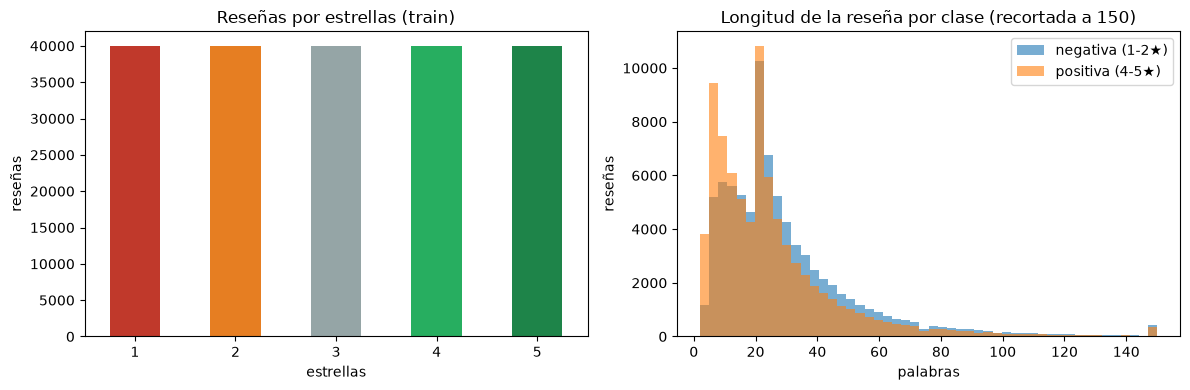

                   count  mean   std  min   25%   50%   75%    max
clase                                                             
negativa (1-2★)  80000.0  29.9  24.4  2.0  15.0  23.0  37.0  506.0
positiva (4-5★)  80000.0  25.2  23.5  2.0  10.0  20.0  31.0  551.0


In [4]:
train["palabras"] = train["text"].str.split().str.len()
sin3 = train[train["estrellas"] != 3].assign(clase=lambda d: np.where(d["estrellas"] <= 2, "negativa (1-2★)", "positiva (4-5★)"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train["estrellas"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#c0392b", "#e67e22", "#95a5a6", "#27ae60", "#1e8449"])
ax[0].set(title="Reseñas por estrellas (train)", xlabel="estrellas", ylabel="reseñas")
ax[0].tick_params(axis="x", rotation=0)
for clase, g in sin3.groupby("clase"):
    ax[1].hist(g["palabras"].clip(upper=150), bins=50, alpha=0.6, label=clase)
ax[1].set(title="Longitud de la reseña por clase (recortada a 150)", xlabel="palabras", ylabel="reseñas")
ax[1].legend()
plt.tight_layout(); plt.show()

print(sin3.groupby("clase")["palabras"].describe().round(1))

In [5]:
pd.set_option("display.max_colwidth", 200)
for e in [1, 3, 5]:
    print(f"--- {e} estrellas ---")
    for t in train[train["estrellas"] == e]["text"].sample(3, random_state=SEED):
        print("•", t)

--- 1 estrellas ---
• Pedí la botella por comodidad al salir a pasear con Sherlock... Pero ha sido una decepción. Cuando llegó tenia el plástico que ancla la botella con el bebedero roto. Me he puesto en contacto con el vendedor y estoy a la espera de noticias...
• lo compré por ser SONY, pero la calidad de sonido me parece pésima. Ni siquiera se oyen los graves ... solo agudos y medios. A los 10min acabé harto
• Decepcionada. El mod venía con claros signos de uso, y la pantalla se ve un fallo en el display. Las baterías venias sin nada de carga, en rojo estaban. En el mismo momento de abrir el paquete, inicie la devolución ya que es un producto muy caro para que te venga usado de otros. Deberían tener más cuidado con las devoluciones y mirar bien todo el producto antes de servirlo a otro cliente. Encima el producto no está disponible de momento.
--- 3 estrellas ---
• Funciona pero me ha llegado sucio y parece usado...
• El producto no tiene mucha calidad, se caen las cerdas con facili

**Lo que vemos:** las cinco clases de estrellas están perfectamente balanceadas (40,000 cada una), así que al quitar las de 3★ queda 50 % negativas y 50 % positivas. No hay nulos. Las reseñas son cortas (mediana de unas 20 palabras), y las negativas tienden a ser algo más largas: quien se queja explica qué salió mal.

## 3. Preparación

**Decisión sobre las de 3 estrellas:** se quitan de entrenamiento y validación, porque son ambiguas (ni buenas ni malas) y la prueba del cliente no las incluye; dejarlas metería ruido justo en la frontera de decisión.

- Entrenamiento: `train` sin 3★ (160,000 reseñas).
- Validación: la partición `validation` sin 3★ (4,000 reseñas). Todas las decisiones salen de aquí.
- Prueba: la del enunciado, intacta hasta la sección 8.
- Cada vectorizador o tokenizador se ajusta **solo con entrenamiento**.

In [6]:
tr = train[train["estrellas"] != 3]
va = val[val["estrellas"] != 3]
X_tr, y_tr = tr["text"].values, (tr["estrellas"] <= 2).astype(int).values
X_val, y_val = va["text"].values, (va["estrellas"] <= 2).astype(int).values
print(f"Entrenamiento: {len(X_tr):,} (negativas {y_tr.mean():.0%}) | Validación: {len(X_val):,} (negativas {y_val.mean():.0%}) | Prueba: {len(X_prueba):,} (negativas {y_prueba.mean():.0%})")

Entrenamiento: 160,000 (negativas 50%) | Validación: 4,000 (negativas 50%) | Prueba: 4,000 (negativas 50%)


## 4. Métricas del cliente

In [7]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, confusion_matrix

def metricas(y_true, prob, umbral=0.5):
    pred = (np.asarray(prob) >= umbral).astype(int)
    rec = recall_score(y_true, pred, zero_division=0)
    prec = precision_score(y_true, pred, zero_division=0)
    return {"exhaustividad": rec, "precision": prec, "exactitud": accuracy_score(y_true, pred),
            "cumple": bool(rec >= 0.90 and prec >= 0.85),
            "margen": min(rec - 0.90, prec - 0.85)}   # cuánto sobra en la especificación más justa

validacion = {}   # métricas de cada modelo en validación

## 5. Línea base

In [8]:
from sklearn.dummy import DummyClassifier
base = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_tr), 1)), y_tr)
prob_base = lambda X: base.predict_proba(np.zeros((len(X), 1)))[:, 1]
validacion["Línea base (clase más frecuente)"] = metricas(y_val, prob_base(X_val))
validacion["Línea base (clase más frecuente)"]

{'exhaustividad': 0.0,
 'precision': 0.0,
 'exactitud': 0.5,
 'cumple': False,
 'margen': -0.9}

Con clases 50/50 la línea base siempre dice «positiva»: exactitud de 0.5 y exhaustividad de 0. Es el piso a superar.

## 6. Modelos

### 6.1 TF-IDF de 1 y 2 gramas + red densa
El vectorizador se ajusta solo con entrenamiento. La red recibe lotes densificados al vuelo para no cargar la matriz completa en memoria. Si la exhaustividad queda justa, la palanca es `class_weight` a favor de la clase negativa (sin mover el umbral); el peso se elige en validación.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(ngram_range=(1, 2), max_features=50_000, min_df=2, sublinear_tf=True)
T_tr = vec.fit_transform(X_tr).astype("float32")
T_val = vec.transform(X_val).astype("float32")
print("Matriz TF-IDF de entrenamiento:", T_tr.shape)

class Lotes(keras.utils.PyDataset):
    """Densifica la matriz dispersa por lotes."""
    def __init__(self, X, y=None, lote=256, barajar=False, **kw):
        super().__init__(**kw); self.X, self.y, self.lote = X, y, lote
        self.idx = np.random.RandomState(SEED).permutation(X.shape[0]) if barajar else np.arange(X.shape[0])
    def __len__(self): return int(np.ceil(self.X.shape[0] / self.lote))
    def __getitem__(self, i):
        j = self.idx[i * self.lote:(i + 1) * self.lote]
        xb = self.X[j].toarray()
        return xb if self.y is None else (xb, self.y[j])

def red_tfidf():
    m = keras.Sequential([keras.Input((T_tr.shape[1],)),
                          keras.layers.Dense(64, activation="relu"),
                          keras.layers.Dropout(0.5),
                          keras.layers.Dense(1, activation="sigmoid")])
    m.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=["accuracy"])
    return m

parada = lambda: [keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)]

modelos_tfidf = {}
for w in [1.0, 1.3]:                      # peso de la clase negativa
    tf.random.set_seed(SEED)
    m = red_tfidf()
    t0 = time.time()
    m.fit(Lotes(T_tr, y_tr, barajar=True), validation_data=Lotes(T_val, y_val), epochs=5,
          class_weight={0: 1.0, 1: w}, callbacks=parada(), verbose=0)
    p = m.predict(Lotes(T_val), verbose=0).ravel()
    modelos_tfidf[w] = m
    validacion[f"TF-IDF + densa (peso neg. {w})"] = metricas(y_val, p)
    print(f"peso {w}: {validacion[f'TF-IDF + densa (peso neg. {w})']}  ({time.time()-t0:.0f} s)")

Matriz TF-IDF de entrenamiento: (160000, 50000)


peso 1.0: {'exhaustividad': 0.927, 'precision': 0.8995633187772926, 'exactitud': 0.91175, 'cumple': True, 'margen': 0.027000000000000024}  (78 s)


peso 1.3: {'exhaustividad': 0.942, 'precision': 0.8899385923476618, 'exactitud': 0.91275, 'cumple': True, 'margen': 0.03993859234766184}  (81 s)


### 6.2 Embedding + Bi-LSTM
`TextVectorization` (adaptado solo con entrenamiento) → Embedding de 64 → LSTM bidireccional de 32 → salida sigmoide.

In [10]:
LARGO = 100
tv = keras.layers.TextVectorization(max_tokens=30_000, output_sequence_length=LARGO)
tv.adapt(X_tr, batch_size=1024)
S_tr, S_val = tv(X_tr).numpy(), tv(X_val).numpy()

tf.random.set_seed(SEED)
bilstm = keras.Sequential([keras.Input((LARGO,), dtype="int64"),
                           keras.layers.Embedding(30_000, 64, mask_zero=True),
                           keras.layers.Bidirectional(keras.layers.LSTM(32)),
                           keras.layers.Dropout(0.3),
                           keras.layers.Dense(1, activation="sigmoid")])
bilstm.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist = bilstm.fit(S_tr, y_tr, validation_data=(S_val, y_val), batch_size=256, epochs=4,
                  callbacks=parada(), verbose=2)
validacion["Embedding + Bi-LSTM"] = metricas(y_val, bilstm.predict(S_val, verbose=0).ravel())
print(validacion["Embedding + Bi-LSTM"], f"({time.time()-t0:.0f} s)")

Epoch 1/4


625/625 - 106s - 169ms/step - accuracy: 0.8753 - loss: 0.3007 - val_accuracy: 0.8992 - val_loss: 0.2432


Epoch 2/4


625/625 - 138s - 221ms/step - accuracy: 0.9228 - loss: 0.2006 - val_accuracy: 0.9050 - val_loss: 0.2346


Epoch 3/4


625/625 - 142s - 227ms/step - accuracy: 0.9418 - loss: 0.1570 - val_accuracy: 0.9032 - val_loss: 0.2483


{'exhaustividad': 0.933, 'precision': 0.8835227272727273, 'exactitud': 0.905, 'cumple': True, 'margen': 0.03300000000000003} (387 s)


### 6.3 BETO ajustado (transformer)
`dccuchile/bert-base-spanish-wwm-cased`, un BERT preentrenado en español. Se ajusta completo en la GPU local (RTX 3050, 4 GB) con precisión mixta, sobre un subconjunto balanceado de 60,000 reseñas de entrenamiento, `max_len` 128, una época y tasa de aprendizaje 2e-5 con calentamiento lineal.

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

BETO = "dccuchile/bert-base-spanish-wwm-cased"
disp = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tok = AutoTokenizer.from_pretrained(BETO)

sub = tr.groupby(tr["estrellas"] <= 2, group_keys=False).sample(30_000, random_state=SEED).sample(frac=1, random_state=SEED)
Xb, yb = sub["text"].values, (sub["estrellas"] <= 2).astype(int).values

def codificar(textos):
    return tok(list(textos), truncation=True, max_length=128, padding="max_length", return_tensors="pt")

def prob_beto(modelo, textos, lote=64):
    modelo.eval(); salida = []
    with torch.no_grad():
        for i in range(0, len(textos), lote):
            enc = {k: v.to(disp) for k, v in codificar(textos[i:i + lote]).items()}
            with torch.autocast(disp.type, dtype=torch.float16, enabled=disp.type == "cuda"):
                logits = modelo(**enc).logits
            salida.append(torch.softmax(logits.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(salida)

torch.manual_seed(SEED)
beto = AutoModelForSequenceClassification.from_pretrained(BETO, num_labels=2).to(disp)
enc_b = codificar(Xb)
LOTE, EPOCAS = 16, 1
pasos = EPOCAS * int(np.ceil(len(yb) / LOTE))
opt = torch.optim.AdamW(beto.parameters(), lr=2e-5, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(opt, int(0.06 * pasos), pasos)
escala = torch.amp.GradScaler(enabled=disp.type == "cuda")

t0 = time.time(); beto.train()
for ep in range(EPOCAS):
    orden = torch.randperm(len(yb), generator=torch.Generator().manual_seed(SEED + ep))
    for k, i in enumerate(range(0, len(yb), LOTE)):
        j = orden[i:i + LOTE]
        with torch.autocast(disp.type, dtype=torch.float16, enabled=disp.type == "cuda"):
            out = beto(input_ids=enc_b["input_ids"][j].to(disp), attention_mask=enc_b["attention_mask"][j].to(disp),
                       token_type_ids=enc_b["token_type_ids"][j].to(disp), labels=torch.tensor(yb[j.numpy()]).to(disp))
        opt.zero_grad(); escala.scale(out.loss).backward(); escala.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(beto.parameters(), 1.0)
        escala.step(opt); escala.update(); sched.step()
        if k % 500 == 0:
            print(f"época {ep+1} paso {k}/{pasos} pérdida {out.loss.item():.3f} ({time.time()-t0:.0f} s)")

validacion["BETO ajustado"] = metricas(y_val, prob_beto(beto, X_val))
print(validacion["BETO ajustado"], f"({time.time()-t0:.0f} s)")

W1107 11:13:18.831000 8828 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

época 1 paso 0/3750 pérdida 0.753 (2 s)


época 1 paso 500/3750 pérdida 0.184 (113 s)


época 1 paso 1000/3750 pérdida 0.353 (224 s)


época 1 paso 1500/3750 pérdida 0.241 (336 s)


época 1 paso 2000/3750 pérdida 0.194 (448 s)


época 1 paso 2500/3750 pérdida 0.355 (559 s)


época 1 paso 3000/3750 pérdida 0.137 (671 s)


época 1 paso 3500/3750 pérdida 0.022 (783 s)


{'exhaustividad': 0.9485, 'precision': 0.9222168206125425, 'exactitud': 0.93425, 'cumple': True, 'margen': 0.04849999999999999} (852 s)


## 7. Comparación en validación y elección

In [12]:
def entrenables_keras(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

parametros = {"Línea base (clase más frecuente)": 0,
              **{f"TF-IDF + densa (peso neg. {w})": entrenables_keras(m) for w, m in modelos_tfidf.items()},
              "Embedding + Bi-LSTM": entrenables_keras(bilstm),
              "BETO ajustado": sum(p.numel() for p in beto.parameters() if p.requires_grad)}

comp = pd.DataFrame(validacion).T.assign(parametros=pd.Series(parametros))
comp = comp[["parametros", "exhaustividad", "precision", "exactitud", "cumple", "margen"]]
comp.round(4)

,parametros,exhaustividad,precision,exactitud,cumple,margen
Línea base (clase más frecuente),0,0.0,0.0,0.5,False,-0.9
TF-IDF + densa (peso neg. 1.0),3200129,0.927,0.899563,0.91175,True,0.027
TF-IDF + densa (peso neg. 1.3),3200129,0.942,0.889939,0.91275,True,0.039939
Embedding + Bi-LSTM,1944897,0.933,0.883523,0.905,True,0.033
BETO ajustado,109852418,0.9485,0.922217,0.93425,True,0.0485


In [13]:
# Regla de elección (solo con validación): entre los que cumplen, el de mayor margen sobre la
# especificación más justa, porque la prueba es otra muestra y queremos holgura.
cumplen = comp[comp["cumple"].astype(bool)]
elegido = (cumplen if len(cumplen) else comp).sort_values(["margen", "parametros"], ascending=[False, True]).index[0]
print("Modelo elegido con validación:", elegido)

# De los TF-IDF solo pasa a la prueba el mejor peso en validación.
mejor_w = max(modelos_tfidf, key=lambda w: validacion[f"TF-IDF + densa (peso neg. {w})"]["margen"])
print("Mejor peso para TF-IDF + densa:", mejor_w)

Modelo elegido con validación: BETO ajustado
Mejor peso para TF-IDF + densa: 1.3


## 8. Evaluación única en prueba y `resultados`
Los modelos ya están congelados. Esta es la única vez que se usa la prueba.

In [14]:
nombre_tfidf = f"TF-IDF + densa (peso neg. {mejor_w})"
prob_prueba = {
    "Línea base (clase más frecuente)": prob_base(X_prueba),
    nombre_tfidf: modelos_tfidf[mejor_w].predict(Lotes(vec.transform(X_prueba).astype("float32")), verbose=0).ravel(),
    "Embedding + Bi-LSTM": bilstm.predict(tv(X_prueba).numpy(), verbose=0).ravel(),
    "BETO ajustado": prob_beto(beto, X_prueba),
}
tipos = {"Línea base (clase más frecuente)": "linea base", nombre_tfidf: "embeddings",
         "Embedding + Bi-LSTM": "recurrente", "BETO ajustado": "transformer"}

filas = []
for nombre, p in prob_prueba.items():
    m = metricas(y_prueba, p)
    filas.append({"modelo": nombre, "tipo": tipos[nombre], "parametros": parametros[nombre],
                  "exhaustividad": round(m["exhaustividad"], 4), "precision": round(m["precision"], 4),
                  "exactitud": round(m["exactitud"], 4), "cumple": m["cumple"], "elegido": nombre == elegido})
resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_resenas.csv", index=False)
resultados

,modelo,tipo,parametros,exhaustividad,precision,exactitud,cumple,elegido
0,Línea base (clase más frecuente),linea base,0,0.0000,0.0000,0.5000,False,False
1,TF-IDF + densa (peso neg. 1.3),embeddings,3200129,0.9410,0.8966,0.9163,True,False
2,Embedding + Bi-LSTM,recurrente,1944897,0.9345,0.8964,0.9133,True,False
3,BETO ajustado,transformer,109852418,0.9570,0.9309,0.9430,True,True


**Nota sobre `tipo`:** la lista del enunciado no tiene una categoría exacta para TF-IDF + red densa; usamos `embeddings` porque es una representación vectorial del texto con un clasificador entrenado encima, que es lo más cercano.

In [15]:
pred = (prob_prueba[elegido] >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_prueba, pred).ravel()
print(f"{elegido} en prueba: de {tp+fn:,} reseñas negativas marcó {tp:,} y se le escaparon {fn:,}; "
      f"de {tp+fp:,} que marcó como negativas, {fp:,} eran positivas.")
print(f"En palabras del cliente: de cada 100 negativas marca {100*tp/(tp+fn):.0f}; de cada 100 que marca, {100*tp/(tp+fp):.0f} sí lo son.")

BETO ajustado en prueba: de 2,000 reseñas negativas marcó 1,914 y se le escaparon 86; de 2,056 que marcó como negativas, 142 eran positivas.
En palabras del cliente: de cada 100 negativas marca 96; de cada 100 que marca, 93 sí lo son.


## 9. Justificación de la elección

**Elegimos BETO ajustado**, con la decisión tomada solo en validación:

| Modelo (validación) | Exhaustividad | Precisión | Margen sobre la especificación más justa |
|---|---|---|---|
| TF-IDF + densa (peso neg. 1.3) | 0.942 | 0.890 | +0.040 |
| Embedding + Bi-LSTM | 0.933 | 0.884 | +0.033 |
| **BETO ajustado** | **0.949** | **0.922** | **+0.049** |

- Los tres modelos cumplen en validación, así que el criterio de desempate fue la **holgura**: la prueba es otra muestra y un modelo que cumple por 3 centésimas puede no cumplir con reseñas nuevas. BETO tiene el mayor margen en las dos métricas.
- La mejora viene de donde el cliente más la necesita: la **precisión** (0.92 contra 0.89), es decir, menos clientes contentos enviados por error a atención a clientes. BETO, al estar preentrenado en español, entiende el contexto («buena calidad, pero…») mejor que contar palabras.
- La prueba, usada una sola vez, confirma la elección: exhaustividad **0.957** y precisión **0.931**, ambas por encima de lo pedido (0.90 y 0.85).
- **Costo:** 110 millones de parámetros y unos 440 MB; clasificar una reseña en CPU tarda decenas de milisegundos, lo cual es suficiente para miles de reseñas al día. Si el cliente necesitara algo más ligero, el plan B es TF-IDF + densa: en prueba también cumple (0.941 y 0.897), con 3.2 millones de parámetros, aunque con menos margen en precisión.
- Peso de clase en TF-IDF: subirlo a 1.3 a favor de las negativas aumentó la exhaustividad (0.927 → 0.942) a cambio de un poco de precisión; se eligió en validación, sin mover el umbral de 0.5.


## 10. Análisis de 3 errores

In [16]:
err = prueba.assign(prob=prob_prueba[elegido], real=y_prueba, pred=pred)
fn_ = err[(err.real == 1) & (err.pred == 0)].sort_values("prob")
fp_ = err[(err.real == 0) & (err.pred == 1)].sort_values("prob", ascending=False)
print(f"Falsos negativos: {len(fn_)} | Falsos positivos: {len(fp_)}")
print("Estrellas de los falsos negativos:", fn_["estrellas"].value_counts().to_dict())
print("Estrellas de los falsos positivos:", fp_["estrellas"].value_counts().to_dict())
print()
pd.set_option("display.max_colwidth", None)
muestra = pd.concat([fn_.head(6), fp_.head(6)])[["estrellas", "prob", "text"]]
muestra.assign(prob=muestra["prob"].round(3))

Falsos negativos: 86 | Falsos positivos: 142
Estrellas de los falsos negativos: {2: 74, 1: 12}
Estrellas de los falsos positivos: {4: 107, 5: 35}



,estrellas,prob,text
1862,2,0.003,Lo que se anuncia . Sin nada raro. A mis gatas les encanta y yo feliz para evitar que salga la arena.
1733,2,0.003,"Tallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo demás perfecto, material de muy buena calidad"
346,1,0.004,Es tal cual lo vi en la fotografía
402,1,0.004,Lo voy a utilizar para regalo de niñas de comunion
182,1,0.006,Producto con evidentes señales de uso
1004,2,0.008,"Tiene buena calidad, no me gusta su estética, pero ya sabemos que para gusto hay colores."
3356,4,0.993,"Despues de esperar mas de dos meses porque estaba sin stock! El paquete ha llegado muy deteriorado, adjunto fotos! Aun no hemos entregado el regalo, esperemos que funcione correctamente!"
3102,4,0.993,La guitarra es muy de plástico y las cuerdas casi no suenan. Se escucha regular
4879,5,0.992,Las devolví. Las compré para mi hija de 6 meses y eran demasiado grandes
3227,4,0.992,"El producto de 10. El envío pésimo, ya que dejar un paquete en un buzón de exterior de una casa cuando está lloviendo a mares. Os podéis imaginar el resultado. Nefasto por parte de la empresa de transporte"


### Tres errores del modelo elegido

En prueba, BETO comete 86 falsos negativos y 142 falsos positivos. **Casi todos están en la frontera:** 74 de los 86 falsos negativos son de 2 estrellas, y 107 de los 142 falsos positivos son de 4 estrellas. Los errores de 1★ contra 5★ son raros.

1. **Falso negativo, 2★ con texto casi positivo** (prob. de negativa 0.003): *«Tallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo demás perfecto, material de muy buena calidad»*. La queja es menor y el resto es elogio («perfecto», «muy buena calidad»). El modelo lee el texto, no las estrellas; un humano también dudaría. Es una limitación de las etiquetas: las estrellas no siempre coinciden con el tono del texto.
2. **Falso negativo, queja educada y subjetiva** (2★, prob. 0.008): *«Tiene buena calidad, no me gusta su estética, pero ya sabemos que para gusto hay colores.»* El cliente está inconforme, pero lo dice sin vocabulario negativo y hasta con tono conciliador. Para Compra Fácil Bajío es un caso de bajo riesgo: no hay un problema que atender.
3. **Falso positivo, queja sobre el envío y no sobre el producto** (4★, prob. 0.992): *«El producto de 10. El envío pésimo, ya que dejar un paquete en un buzón de exterior… Nefasto por parte de la empresa de transporte»*. El modelo reacciona a «pésimo» y «nefasto». Aquí el error **le conviene al cliente**: hay un problema real de paquetería que atención a clientes sí debería ver, aunque la persona le haya dado 4 estrellas al producto.

**Conclusión:** los errores no son del tipo «no entendió una reseña claramente enojada», sino reseñas mixtas donde las estrellas y el texto no coinciden. Mejorar más requeriría separar la queja sobre el producto de la queja sobre el envío, o reentrenar con etiquetas revisadas por personas.


## 11. Guardar el modelo elegido

In [17]:
os.makedirs("modelo", exist_ok=True)
if elegido == "BETO ajustado":
    # ~440 MB: no cabe en GitHub (límite 100 MB). Se guarda fuera del repo y se sube a Hugging Face.
    destino = os.path.abspath(os.path.join("..", "..", "beto_resenas"))
    beto.save_pretrained(destino); tok.save_pretrained(destino)
    print("BETO guardado en", destino, "-> subir a Hugging Face y poner el enlace en el README")
else:
    import pickle
    modelo_final = {nombre_tfidf: modelos_tfidf[mejor_w], "Embedding + Bi-LSTM": bilstm}[elegido]
    modelo_final.save("modelo/modelo_resenas.keras")
    if elegido == nombre_tfidf:
        pickle.dump(vec, open("modelo/vectorizador_tfidf.pkl", "wb"))
    print("Guardado en resenas/modelo/")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BETO guardado en C:\IBERO\A7Semestre\ML_III\Segundo_Pacial\beto_resenas -> subir a Hugging Face y poner el enlace en el README
